# Predicción del puntaje global de la prueba Saber 11: preparación de datos y modelo de referencia

### Andrés Giovanny Rubiano Muñoz "Andy Rubiano"

**Maestría en Inteligencia Artificial**
**Universidad de La Salle**

**Ciencia de Datos**

---

**Actividad:** Proyecto Integrador de Ciencia de Datos | Fase 2 · Actividades 3 y 4: *Limpieza de datos e ingeniería de variables* y *Partición de datos y modelo base* (**Entregable 2**).

**Caso de estudio:** *Resultados únicos Saber 11*, ICFES, periodo **2022-4**, consumido desde la copia congelada en Kaggle [`andyrubiano/saber-11-resultados-2022-4`](https://www.kaggle.com/datasets/andyrubiano/saber-11-resultados-2022-4) (CC BY-SA 4.0).

**Variable objetivo:** `punt_global` (0 a 500). **Tarea:** regresión.

**Punto de partida:** las doce decisiones de preparación que dejó el análisis exploratorio del Entregable 1 (cuaderno `01_planteamiento_y_eda.ipynb`).

**Producto de este cuaderno:** el conjunto de datos limpio con sus variables derivadas, la partición fija en entrenamiento, validación y prueba, dos preprocesadores (uno para modelos lineales y otro para modelos de árboles) y un modelo de referencia con su métrica inicial. Todo queda guardado en `data/processed/` y `models/` para que los cuadernos de las fases 3 y 4 trabajen sobre exactamente las mismas filas.

## 1. Objetivo y decisiones heredadas de la fase 1

Este cuaderno cubre el **objetivo específico 3** del proyecto: preparar los datos (tratamiento de valores faltantes y atípicos, codificación de variables ordinales y nominales, ingeniería de variables), separar entrenamiento, validación y prueba, y establecer un modelo de referencia (*baseline*) con su métrica inicial.

El análisis exploratorio del Entregable 1 dejó doce decisiones que aquí se implementan una por una:

| # | Decisión | Dónde se aplica |
|---|---|---|
| 1 | Eliminar duplicados **antes** de particionar | Sección 3 |
| 2 | Excluir los puntajes por área y `desemp_ingles` (fuga de información) | Sección 4.1 |
| 3 | Conservar los faltantes del cuestionario como categoría *No respondió* y agregar un indicador de cuestionario incompleto | Sección 4.3 |
| 4 | Descartar constantes, casi constantes, identificadores, nombres y columnas de residencia y presentación | Sección 4.1 |
| 5 | Educación de los padres como ordinal 0 a 9, con *No sabe* como nivel propio | Sección 5.1 |
| 6 | Estrato como nominal (se quiebra en los niveles 5 y 6) | Sección 5.2 |
| 7 | Crear *personas por cuarto* y tratar personas y cuartos como categóricas | Sección 5.1 |
| 8 | Edad numérica e indicador de extraedad; descartar `estu_tipodocumento` | Sección 4.2 |
| 9 | Jornada, naturaleza, área y carácter como nominales, más la interacción naturaleza × área | Sección 5.2 |
| 10 | Indicador bilingüe conservado con la categoría *No reportado* | Sección 4.3 |
| 11 | Departamento con *one-hot*; municipio con codificación por objetivo calculada solo en entrenamiento | Sección 7 |
| 12 | Regresión lineal regularizada como modelo de referencia | Sección 8 |

Las reglas de cómputo (partición estratificada por deciles, dos representaciones de las variables, semilla fija, artefactos guardados) vienen del plan `docs/plan-computo-colab.md`.

## 2. Preparación del entorno

Las dependencias (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `kagglehub`, `joblib`) vienen preinstaladas en Google Colab; localmente se instalan con `pip install -r requirements.txt` en el entorno virtual del proyecto. Se importan agrupadas por propósito y se resuelven las rutas: dentro del repositorio, los artefactos se guardan en `data/processed/` y `models/`, y las figuras en `assets/images/data/`; en Colab se crea la misma estructura bajo `/content/saber11-project`.

In [1]:
import os, sys, time, warnings, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import sklearn
import joblib
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

print("pandas:", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__,
      "| matplotlib:", matplotlib.__version__, "| kagglehub:", kagglehub.__version__)

IN_COLAB = "google.colab" in sys.modules

def find_project_root(start=Path.cwd()):
    """Sube por el árbol de carpetas hasta encontrar la raíz del repositorio (README.md + notebooks/)."""
    for candidate in [start, *start.parents]:
        if (candidate / "README.md").exists() and (candidate / "notebooks").is_dir():
            return candidate
    return start

PROJECT_ROOT = Path("/content/saber11-project") if IN_COLAB else find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
FIG_DIR = PROJECT_ROOT / "assets" / "images" / "data"
for folder in (PROCESSED_DIR, MODELS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Entorno          : {'Google Colab' if IN_COLAB else 'local'}")
print(f"Raíz del proyecto: {PROJECT_ROOT}")

pandas: 3.0.6 | numpy: 2.5.4 | scikit-learn: 1.9.1 | matplotlib: 3.11.2 | kagglehub: 1.0.2
Entorno          : local
Raíz del proyecto: D:\Universidad de La Salle\2do semestre\Ciencia de datos\Proyecto final\saber11-project


Se fija la misma identidad gráfica del cuaderno anterior (paleta, estilo de ejes, 110 dpi), la semilla global `RANDOM_STATE = 42` que gobierna la partición y cualquier muestreo, y dos funciones auxiliares: `save_fig`, que guarda las figuras donde las toma el informe, y `evaluar`, que calcula las tres métricas de regresión del proyecto para un vector de predicciones:

*   **MAE** (error absoluto medio): cuántos puntos de la escala se equivoca el modelo en promedio. Es la métrica más comunicable.
*   **RMSE** (raíz del error cuadrático medio): castiga los errores grandes; su brecha con el MAE delata predicciones muy desviadas.
*   **R²** (coeficiente de determinación): fracción de la varianza del puntaje que el modelo explica; 0 equivale a predecir siempre la media.

In [2]:
C_BASE, C_ACCENT, C_NEU = "#2a78d6", "#eb6834", "#5B7C99"
TINTA, GRIS = "#0b0b0b", "#52514e"
PALETTE = [C_BASE, C_ACCENT, "#2CA02C", "#9467BD", "#8C564B", "#E377C2", "#7F7F7F", "#BCBD22"]

sns.set_style("whitegrid")
sns.set_palette(PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#d9d8d3", "axes.labelcolor": GRIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "grid.color": "#eeede9", "grid.linewidth": 0.8,
})

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def save_fig(fig, name):
    """Guarda la figura en assets/images/data/<name>.png."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"Figura guardada: {path.relative_to(PROJECT_ROOT) if path.is_relative_to(PROJECT_ROOT) else path}")

def evaluar(y_true, y_pred):
    """MAE, RMSE y R² en un diccionario, redondeados para las tablas."""
    return {"MAE": round(mean_absolute_error(y_true, y_pred), 2),
            "RMSE": round(root_mean_squared_error(y_true, y_pred), 2),
            "R2": round(r2_score(y_true, y_pred), 4)}

### 2.1 Control de tiempo

El plan de cómputo pide una celda que mida la velocidad del entorno antes de empezar: entrena un *gradient boosting* de 50 iteraciones sobre 50.000 filas sintéticas y reporta los segundos. En este cuaderno el resultado es solo informativo (la fase 2 no hace búsquedas costosas); en el cuaderno de la fase 3 esa misma medición decide cuántas combinaciones de hiperparámetros se exploran.

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
X_sint = rng.normal(size=(50_000, 20))
y_sint = X_sint[:, :5].sum(axis=1) + rng.normal(scale=0.5, size=50_000)
t0 = time.time()
HistGradientBoostingRegressor(max_iter=50, random_state=RANDOM_STATE).fit(X_sint, y_sint)
SEGUNDOS_CONTROL = time.time() - t0
MODO_RAPIDO = SEGUNDOS_CONTROL > 15
print(f"Boosting de control (50 iteraciones, 50.000 filas): {SEGUNDOS_CONTROL:.1f} s "
      f"→ {'entorno lento: modo rápido activado' if MODO_RAPIDO else 'entorno dentro del presupuesto'}")
del X_sint, y_sint

Boosting de control (50 iteraciones, 50.000 filas): 0.2 s → entorno dentro del presupuesto


En este equipo el boosting de control tarda una fracción de segundo, muy por debajo del umbral de 15 s, así que el entorno queda dentro del presupuesto y `MODO_RAPIDO` permanece en `False`. En Colab gratuito la cifra será mayor; el cuaderno la imprime para que quede registrada en cada ejecución.

## 3. Carga desde Kaggle y deduplicación

El cuaderno descarga únicamente el archivo Parquet de la copia congelada en Kaggle (31,5 MB, sin cuenta) y aplica de inmediato la **decisión 1**: eliminar los duplicados exactos que trae el portal, de modo que cada estudiante aparezca una sola vez antes de cualquier partición. Se verifica que el resultado coincide con lo documentado en la fase 1 (532.792 estudiantes con `estu_consecutivo` único).

In [4]:
KAGGLE_DATASET = "andyrubiano/saber-11-resultados-2022-4"
PARQUET_FILE = "saber11_20224.parquet"

t0 = time.time()
parquet_path = kagglehub.dataset_download(KAGGLE_DATASET, path=PARQUET_FILE)
raw = pd.read_parquet(parquet_path)
n_raw = len(raw)
df = raw.drop_duplicates().reset_index(drop=True)
del raw

print(f"Fuente   : Kaggle · {KAGGLE_DATASET} · {PARQUET_FILE} (origen: ICFES, datos.gov.co kgxf-xxbe, CC BY-SA 4.0)")
print(f"Filas publicadas: {n_raw:,} | tras eliminar duplicados: {len(df):,} | "
      f"estu_consecutivo único: {df['estu_consecutivo'].is_unique} | carga: {time.time() - t0:.1f} s")
assert len(df) == 532_792 and df["estu_consecutivo"].is_unique, "El conjunto no coincide con el documentado en la fase 1"

Fuente   : Kaggle · andyrubiano/saber-11-resultados-2022-4 · saber11_20224.parquet (origen: ICFES, datos.gov.co kgxf-xxbe, CC BY-SA 4.0)
Filas publicadas: 1,065,888 | tras eliminar duplicados: 532,792 | estu_consecutivo único: True | carga: 1.9 s


La carga desde Kaggle toma unos segundos y la deduplicación reproduce exactamente el resultado de la fase 1: de **1.065.888 filas publicadas** quedan **532.792 estudiantes**, con identificador único. La aserción de la celda garantiza que el resto del cuaderno no corra sobre un conjunto distinto al documentado.

## 4. Limpieza de datos

### 4.1 Columnas que salen del conjunto

Se descartan cuatro grupos de columnas, cada uno por una razón distinta documentada en la fase 1:

*   **Fuga de información** (decisión 2): los cinco puntajes por área y el nivel de inglés, porque el puntaje global es una función exacta de ellos.
*   **Sin información** (decisión 4): `periodo` y `estu_estudiante` son constantes; `estu_estadoinvestigacion` y `estu_privado_libertad` tienen más del 99,9 % en un solo valor.
*   **Identificadores y nombres** (decisión 4): códigos DANE e ICFES y nombres del establecimiento y la sede identifican a la entidad, no la describen; `estu_consecutivo` se conserva solo como índice de trazabilidad.
*   **Columnas redundantes** (decisiones 4 y 8): lugar de residencia y de presentación de la prueba replican la ubicación del colegio; nacionalidad y país de residencia son casi constantes; `estu_tipodocumento` duplica la información de la edad.

In [5]:
TARGET = "punt_global"
LEAK_COLS = ["punt_lectura_critica", "punt_matematicas", "punt_sociales_ciudadanas",
             "punt_c_naturales", "punt_ingles", "desemp_ingles"]
CONST_COLS = ["periodo", "estu_estudiante", "estu_estadoinvestigacion", "estu_privado_libertad"]
ID_COLS = ["cole_cod_dane_establecimiento", "cole_cod_dane_sede", "cole_codigo_icfes",
           "cole_nombre_establecimiento", "cole_nombre_sede", "cole_cod_depto_ubicacion",
           "cole_cod_mcpio_ubicacion"]
REDUNDANT_COLS = ["estu_cod_depto_presentacion", "estu_cod_mcpio_presentacion", "estu_depto_presentacion",
                  "estu_mcpio_presentacion", "estu_cod_reside_depto", "estu_cod_reside_mcpio",
                  "estu_depto_reside", "estu_mcpio_reside", "estu_nacionalidad", "estu_pais_reside",
                  "estu_tipodocumento"]

df = df.set_index("estu_consecutivo")
df = df.drop(columns=LEAK_COLS + CONST_COLS + ID_COLS + REDUNDANT_COLS)
print(f"Columnas conservadas ({df.shape[1]}): {df.columns.tolist()}")

Columnas conservadas (22): ['cole_area_ubicacion', 'cole_bilingue', 'cole_calendario', 'cole_caracter', 'cole_depto_ubicacion', 'cole_genero', 'cole_jornada', 'cole_mcpio_ubicacion', 'cole_naturaleza', 'cole_sede_principal', 'estu_fechanacimiento', 'estu_genero', 'fami_cuartoshogar', 'fami_educacionmadre', 'fami_educacionpadre', 'fami_estratovivienda', 'fami_personashogar', 'fami_tieneautomovil', 'fami_tienecomputador', 'fami_tieneinternet', 'fami_tienelavadora', 'punt_global']


De las 51 columnas originales quedan **22**: 21 variables candidatas y la variable objetivo. Salieron 6 por fuga de información, 4 por no tener variación, 7 identificadores y nombres, y 11 redundantes; el identificador del estudiante pasó a ser el índice del `DataFrame`, de modo que cada fila sigue siendo rastreable sin que entre al modelo.

### 4.2 Edad, valores atípicos e indicador de extraedad

La fecha de nacimiento se convierte en la **edad al presentar la prueba** (4 de septiembre de 2022). Las fechas no interpretables y las edades fuera de [13, 80] años se tratan como faltantes y se imputan con la mediana, porque son muy pocas (menos de 300) y la edad es una de las variables más informativas. Se crea el indicador de **extraedad** (19 años o más), que en la fase 1 marcó la caída de puntaje asociada a la educación de adultos (decisión 8).

Sobre los **valores atípicos** del puntaje global se toma una decisión explícita: se conservan. El diagrama de caja de la fase 1 muestra valores extremos por encima de 400 y un mínimo de 0, pero son puntajes reales de estudiantes reales, no errores de medición; eliminarlos sesgaría el modelo contra justamente los casos que más interesa entender. La celda cuantifica cuántos quedan fuera del criterio de 1,5 rangos intercuartílicos y cuántos son exactamente cero, para que la decisión quede documentada.

In [6]:
FECHA_PRUEBA = pd.Timestamp("2022-09-04")
fecha_nac = pd.to_datetime(df["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")
df["edad"] = ((FECHA_PRUEBA - fecha_nac).dt.days / 365.25).round(1)
fuera = (df["edad"] < 13) | (df["edad"] > 80)
df.loc[fuera, "edad"] = np.nan
edad_faltante = df["edad"].isna().sum()
df["edad"] = df["edad"].fillna(df["edad"].median())
df["extraedad"] = (df["edad"] >= 19).astype("int8")
df = df.drop(columns=["estu_fechanacimiento"])
print(f"Edades no válidas imputadas con la mediana ({df['edad'].median():.1f} años): {edad_faltante:,}")
print(f"Estudiantes en extraedad (≥ 19 años): {df['extraedad'].sum():,} ({df['extraedad'].mean() * 100:.1f} %)")

q1, q3 = df[TARGET].quantile([0.25, 0.75])
iqr = q3 - q1
atipicos = (df[TARGET] < q1 - 1.5 * iqr) | (df[TARGET] > q3 + 1.5 * iqr)
print(f"\nPuntaje global: Q1 = {q1:.0f}, Q3 = {q3:.0f}, límites de Tukey [{q1 - 1.5 * iqr:.0f}, {q3 + 1.5 * iqr:.0f}]")
print(f"Valores atípicos por el criterio de 1,5 IQR: {atipicos.sum():,} ({atipicos.mean() * 100:.2f} %) → se conservan")
print(f"Puntajes exactamente 0: {(df[TARGET] == 0).sum():,} → se conservan")

Edades no válidas imputadas con la mediana (17.2 años): 299
Estudiantes en extraedad (≥ 19 años): 58,591 (11.0 %)

Puntaje global: Q1 = 210, Q3 = 288, límites de Tukey [93, 405]
Valores atípicos por el criterio de 1,5 IQR: 696 (0.13 %) → se conservan
Puntajes exactamente 0: 4 → se conservan


Solo **299 edades** no eran válidas y se imputaron con la mediana de 17,2 años. El indicador de extraedad marca a **58.591 estudiantes (11,0 %)**, que en la fase 1 promediaban entre 199 y 230 puntos frente a 265 de los de 16 y 17 años; es una de las variables con más poder de la tabla.

Sobre los valores atípicos, el criterio de Tukey marca como extremos los puntajes fuera de [93, 405], que son **696 estudiantes (0,13 %)**, y solo **4** tienen puntaje exactamente cero. Son tan pocos y tan reales que conservarlos no afecta a los modelos y eliminarlos habría borrado justamente a los estudiantes de mejor y peor desempeño.

### 4.3 Valores faltantes

La fase 1 mostró que los faltantes del cuestionario **no son aleatorios**: quienes no lo responden obtienen 21,5 puntos menos. Por eso no se eliminan filas ni se imputan valores que borren esa señal (decisión 3). El tratamiento es:

*   En las variables **categóricas** del hogar y del colegio (`fami_*`, `cole_bilingue`, `cole_caracter`) el faltante se convierte en la categoría explícita **`No respondió`** (o `No reportado` para las del colegio), que los modelos tratan como un nivel más (decisión 10).
*   Se crea el indicador **`cuestionario_incompleto`** (1 si falta al menos una respuesta del bloque `fami_*`).
*   Las dos columnas del colegio con un par de faltantes (`cole_area_ubicacion`, `cole_naturaleza`, etc.) se rellenan con la moda, porque son dos registros sobre medio millón.

Al final no debe quedar ningún faltante en el conjunto.

In [7]:
FAMI_COLS = [c for c in df.columns if c.startswith("fami_")]
df["cuestionario_incompleto"] = df[FAMI_COLS].isna().any(axis=1).astype("int8")

def agregar_categoria(serie, etiqueta):
    serie = serie.cat.add_categories([etiqueta]) if etiqueta not in serie.cat.categories else serie
    return serie.fillna(etiqueta)

for col in FAMI_COLS:
    df[col] = agregar_categoria(df[col], "No respondió")
for col in ["cole_bilingue", "cole_caracter"]:
    df[col] = agregar_categoria(df[col], "No reportado")

restantes = df.columns[df.isna().any()].tolist()
for col in restantes:
    df[col] = df[col].fillna(df[col].mode().iloc[0])
print(f"Cuestionario incompleto: {df['cuestionario_incompleto'].sum():,} estudiantes ({df['cuestionario_incompleto'].mean() * 100:.2f} %)")
print(f"Columnas rellenadas con la moda (faltantes residuales): {restantes}")
print(f"Faltantes que quedan en el conjunto: {int(df.isna().sum().sum())}")

Cuestionario incompleto: 54,026 estudiantes (10.14 %)
Columnas rellenadas con la moda (faltantes residuales): ['cole_area_ubicacion', 'cole_calendario', 'cole_depto_ubicacion', 'cole_genero', 'cole_jornada', 'cole_mcpio_ubicacion', 'cole_naturaleza', 'cole_sede_principal', 'estu_genero']
Faltantes que quedan en el conjunto: 0


El indicador de cuestionario incompleto marca a **54.026 estudiantes (10,14 %)**, la misma cifra de la fase 1. Las nueve columnas rellenadas con la moda tenían uno o dos faltantes cada una (en total, dos registros), así que la imputación es inocua. Tras este paso el conjunto **no tiene ningún faltante**; los que reaparecen en la sección siguiente son faltantes creados a propósito en las variables ordinales derivadas, para que *No sabe* y *No respondió* no reciban un número que no les corresponde.

## 5. Ingeniería de variables

### 5.1 Variables ordinales y derivadas

*   **Educación de la madre y del padre** (decisión 5): se codifican de 0 (*Ninguno*) a 9 (*Postgrado*) respetando el orden de los niveles. Las respuestas *No sabe*, *No Aplica* y *No respondió* no tienen posición en esa escala: quedan como faltante en la columna ordinal y se registran en un indicador propio (`educ_madre_desconocida`, `educ_padre_desconocida`), de modo que el modelo lineal las imputa con la mediana sin perder la señal y el de árboles las trata de forma nativa. Así *No sabe* sigue siendo un nivel propio, como pedía la fase 1, sin romper la ordinalidad.
*   **Personas por cuarto** (decisión 7): la fase 1 encontró que personas y cuartos tienen relación en forma de U con el puntaje. Se construye una medida de hacinamiento a partir del punto medio de cada tramo (1 a 2 → 1,5 personas; *Seis o mas* → 6 cuartos) y se conservan ambas variables originales como categóricas. Cuando el estudiante no respondió alguna de las dos preguntas, la razón queda como faltante y recibe el mismo tratamiento que la educación de los padres: mediana en el modelo lineal, `NaN` nativo en los árboles, y la categoría *No respondió* de las variables originales conserva la señal.
*   **Género** del estudiante como binaria.

In [8]:
EDU_NIVEL = {"Ninguno": 0, "Primaria incompleta": 1, "Primaria completa": 2,
             "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
             "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
             "Educación profesional incompleta": 7, "Educación profesional completa": 8, "Postgrado": 9}
PERSONAS_MEDIO = {"1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5, "7 a 8": 7.5, "9 o más": 9.5}
CUARTOS_MEDIO = {"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6}

for padre, col in [("madre", "fami_educacionmadre"), ("padre", "fami_educacionpadre")]:
    ordinal = df[col].astype(object).map(EDU_NIVEL)
    df[f"educ_{padre}_ord"] = ordinal.astype("float32")
    df[f"educ_{padre}_desconocida"] = ordinal.isna().astype("int8")

personas = df["fami_personashogar"].astype(object).map(PERSONAS_MEDIO)
cuartos = df["fami_cuartoshogar"].astype(object).map(CUARTOS_MEDIO)
df["personas_por_cuarto"] = (personas / cuartos).astype("float32")
df["genero_F"] = (df["estu_genero"] == "F").astype("int8")
df = df.drop(columns=["estu_genero"])

print("Educación de la madre (ordinal 0-9):")
display(df["educ_madre_ord"].describe().round(2).to_frame().T)
print(f"Nivel desconocido: madre {df['educ_madre_desconocida'].mean() * 100:.1f} % · padre {df['educ_padre_desconocida'].mean() * 100:.1f} %")
print("\nPersonas por cuarto:")
display(df["personas_por_cuarto"].describe().round(2).to_frame().T)

Educación de la madre (ordinal 0-9):


,count,mean,std,min,25%,50%,75%,max
educ_madre_ord,"488,045.00",4.19,2.31,0.00,3.00,4.00,6.00,9.00


Nivel desconocido: madre 8.4 % · padre 13.9 %

Personas por cuarto:


,count,mean,std,min,25%,50%,75%,max
personas_por_cuarto,"507,786.00",1.71,0.84,0.25,1.17,1.75,1.83,9.50


La educación de la madre codificada va de 0 a 9 con **mediana 4** (secundaria completa) y media 4,19; el nivel es desconocido para el **8,4 %** de las madres y el **13,9 %** de los padres, diferencia que refleja los hogares sin presencia paterna que detectó la fase 1 y que el indicador `educ_padre_desconocida` conserva como información. La razón de personas por cuarto tiene mediana 1,75 y llega hasta 9,5 (nueve o más personas en un cuarto), con 25.006 faltantes que corresponden a quienes no respondieron alguna de las dos preguntas.

### 5.2 Variables nominales e interacción naturaleza × área

El estrato se deja como nominal porque la fase 1 mostró que su relación con el puntaje se quiebra en los niveles 5 y 6 (decisión 6). Las variables del colegio (naturaleza, área, jornada, carácter, calendario, género, sede principal, bilingüe) también son nominales (decisión 9). Como el cruce de la fase 1 reveló que la brecha urbano-rural se invierte en los colegios privados, se crea la variable **`naturaleza_area`** con las cuatro combinaciones, que un modelo lineal no puede inferir por sí solo.

Al cerrar esta sección se fija la lista definitiva de variables explicativas, separadas por el tratamiento que recibirán en el preprocesamiento.

In [9]:
df["naturaleza_area"] = (df["cole_naturaleza"].astype(str) + " · " + df["cole_area_ubicacion"].astype(str)).astype("category")

NUM_COLS = ["edad", "educ_madre_ord", "educ_padre_ord", "personas_por_cuarto"]
BIN_COLS = ["extraedad", "cuestionario_incompleto", "educ_madre_desconocida", "educ_padre_desconocida", "genero_F"]
NOM_COLS = ["fami_estratovivienda", "fami_personashogar", "fami_cuartoshogar", "fami_tieneinternet",
            "fami_tienecomputador", "fami_tieneautomovil", "fami_tienelavadora",
            "cole_naturaleza", "cole_area_ubicacion", "naturaleza_area", "cole_jornada", "cole_caracter",
            "cole_calendario", "cole_genero", "cole_sede_principal", "cole_bilingue", "cole_depto_ubicacion"]
HIGH_CARD_COLS = ["cole_mcpio_ubicacion"]
FEATURES = NUM_COLS + BIN_COLS + NOM_COLS + HIGH_CARD_COLS

df = df.drop(columns=["fami_educacionmadre", "fami_educacionpadre"])
assert set(FEATURES) == set(df.columns) - {TARGET}, set(df.columns) ^ set(FEATURES) ^ {TARGET}
for col in NOM_COLS + HIGH_CARD_COLS:
    df[col] = df[col].astype("category").cat.remove_unused_categories()

resumen = pd.DataFrame({
    "grupo": (["numérica"] * len(NUM_COLS) + ["binaria"] * len(BIN_COLS)
              + ["nominal"] * len(NOM_COLS) + ["alta cardinalidad"] * len(HIGH_CARD_COLS)),
    "niveles": [df[c].nunique() for c in FEATURES],
}, index=FEATURES)
print(f"Variables explicativas: {len(FEATURES)} | objetivo: {TARGET} | filas: {len(df):,}")
display(resumen.T)

Variables explicativas: 27 | objetivo: punt_global | filas: 532,792


,edad,educ_madre_ord,educ_padre_ord,personas_por_cuarto,extraedad,cuestionario_incompleto,educ_madre_desconocida,educ_padre_desconocida,genero_F,fami_estratovivienda,fami_personashogar,fami_cuartoshogar,fami_tieneinternet,fami_tienecomputador,fami_tieneautomovil,fami_tienelavadora,cole_naturaleza,cole_area_ubicacion,naturaleza_area,cole_jornada,cole_caracter,cole_calendario,cole_genero,cole_sede_principal,cole_bilingue,cole_depto_ubicacion,cole_mcpio_ubicacion
grupo,numérica,numérica,numérica,numérica,binaria,binaria,binaria,binaria,binaria,nominal,nominal,nominal,nominal,nominal,nominal,nominal,nominal,nominal,nominal,nominal,nominal,nominal,nominal,nominal,nominal,nominal,alta cardinalidad
niveles,559,10,10,29,2,2,2,2,2,8,6,7,3,3,3,3,2,2,4,6,5,3,3,2,3,33,1031


El conjunto de trabajo queda con **27 variables explicativas** para 532.792 estudiantes: 4 numéricas, 5 binarias, 17 nominales (de 2 a 33 niveles, incluida la nueva `naturaleza_area` con 4 combinaciones) y el municipio con 1.031 niveles, que recibe un tratamiento aparte. Son cinco más que las 22 estimadas en la fase 1 porque las variables derivadas (edad, extraedad, personas por cuarto, indicadores de desconocido e incompleto) se suman a las originales que las generaron.

## 6. Partición en entrenamiento, validación y prueba

Se separa el conjunto en **70 % entrenamiento, 15 % validación y 15 % prueba** con semilla fija, estratificando por deciles del puntaje global para que las tres partes tengan la misma distribución de la variable objetivo. La partición se hace **después** de la deduplicación, así que ningún estudiante puede quedar en dos partes. Los índices (`estu_consecutivo`) se guardan en `data/processed/particion.parquet` y el conjunto limpio en `data/processed/saber11_fase2.parquet`, de modo que las fases 3 y 4 trabajen con exactamente las mismas filas.

Cada parte tiene un papel distinto: el entrenamiento ajusta los modelos, la validación compara configuraciones y elige hiperparámetros, y la prueba se usa **una sola vez** al final de cada fase para reportar el desempeño.

Solapamiento entre partes: 0


,count,mean,std,min,25%,50%,75%,max
entrenamiento,"372,954.00",250.10,51.80,0.00,210.00,247.00,288.00,477.00
validación,"79,919.00",250.10,51.80,0.00,210.00,247.00,287.00,477.00
prueba,"79,919.00",250.10,51.80,0.00,210.00,247.00,288.00,456.00


Figura guardada: assets\images\data\split_check.png


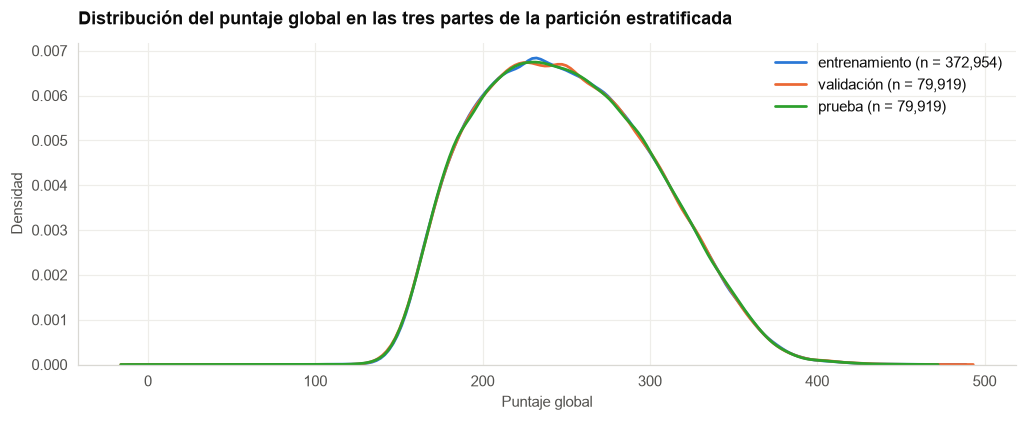

In [10]:
deciles = pd.qcut(df[TARGET], q=10, labels=False).to_numpy()
posiciones = np.arange(len(df))
pos_train, pos_temp = train_test_split(posiciones, test_size=0.30, random_state=RANDOM_STATE, stratify=deciles)
pos_val, pos_test = train_test_split(pos_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=deciles[pos_temp])
idx_train, idx_val, idx_test = df.index[pos_train], df.index[pos_val], df.index[pos_test]

particion = pd.Series("train", index=df.index, name="particion")
particion.loc[idx_val] = "val"
particion.loc[idx_test] = "test"
particion = particion.astype("category")

df.to_parquet(PROCESSED_DIR / "saber11_fase2.parquet")
particion.to_frame().to_parquet(PROCESSED_DIR / "particion.parquet")
json.dump({"NUM_COLS": NUM_COLS, "BIN_COLS": BIN_COLS, "NOM_COLS": NOM_COLS,
           "HIGH_CARD_COLS": HIGH_CARD_COLS, "TARGET": TARGET},
          open(PROCESSED_DIR / "columnas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

X, y = df[FEATURES], df[TARGET]
X_train, y_train = X.loc[idx_train], y.loc[idx_train]
X_val, y_val = X.loc[idx_val], y.loc[idx_val]
X_test, y_test = X.loc[idx_test], y.loc[idx_test]

control = pd.DataFrame({
    "entrenamiento": y_train.describe(), "validación": y_val.describe(), "prueba": y_test.describe()}).round(1)
print(f"Solapamiento entre partes: {len(set(idx_train) & set(idx_val) | set(idx_train) & set(idx_test) | set(idx_val) & set(idx_test))}")
display(control.T)

fig, ax = plt.subplots(figsize=(11, 3.8))
for nombre, serie, color in [("entrenamiento", y_train, C_BASE), ("validación", y_val, C_ACCENT), ("prueba", y_test, "#2CA02C")]:
    sns.kdeplot(serie, ax=ax, color=color, linewidth=1.8, label=f"{nombre} (n = {len(serie):,})")
ax.set_title("Distribución del puntaje global en las tres partes de la partición estratificada")
ax.set_xlabel("Puntaje global"); ax.set_ylabel("Densidad"); ax.legend(frameon=False)
save_fig(fig, "split_check")
plt.show()

La partición deja **372.954 estudiantes en entrenamiento, 79.919 en validación y 79.919 en prueba**, sin ningún identificador compartido entre partes. La estratificación funciona: las tres tienen media 250,1, desviación 51,8 y los mismos cuartiles (210, 247, 288), y las tres curvas de densidad se superponen hasta ser indistinguibles. Cualquier diferencia de métrica entre partes se deberá al modelo y no a la muestra.

## 7. Preprocesamiento: dos representaciones de las variables

El plan de cómputo fija una representación por familia de modelos, y ambas se construyen como `ColumnTransformer` de scikit-learn para que **se ajusten solo con entrenamiento** y se apliquen sin fuga a validación y prueba:

*   **`prep_lineal`**, para los modelos lineales: las nominales se expanden con *one-hot*; las numéricas ordinales con faltante (educación de los padres) se imputan con la mediana; todas las numéricas se estandarizan; y el municipio, con más de mil niveles, se codifica por objetivo con `TargetEncoder`, que usa validación cruzada interna para que el valor de cada fila no incluya su propio puntaje.
*   **`prep_arboles`**, para boosting y bosques aleatorios: las nominales pasan a códigos enteros con `OrdinalEncoder` (los faltantes y categorías no vistas quedan en −1), las numéricas se dejan tal cual (los árboles no necesitan escala y manejan `NaN` de forma nativa) y el municipio también se codifica por objetivo. La máscara de columnas categóricas se guarda para que `HistGradientBoostingRegressor` las trate como categorías y no como números.

Ambos preprocesadores se guardan con `joblib` en `models/`.

In [11]:
prep_lineal = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_COLS),
    ("bin", "passthrough", BIN_COLS),
    ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), NOM_COLS),
    ("mcpio", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), HIGH_CARD_COLS),
], verbose_feature_names_out=False).set_output(transform="pandas")

prep_arboles = ColumnTransformer([
    ("num", "passthrough", NUM_COLS),
    ("bin", "passthrough", BIN_COLS),
    ("nom", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1,
                           dtype=np.float32), NOM_COLS),
    ("mcpio", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), HIGH_CARD_COLS),
], verbose_feature_names_out=False).set_output(transform="pandas")

t0 = time.time()
Xl_train = prep_lineal.fit_transform(X_train, y_train)
Xa_train = prep_arboles.fit_transform(X_train, y_train)
CAT_MASK = [c in NOM_COLS for c in Xa_train.columns]
print(f"Representación lineal : {Xl_train.shape[1]} columnas | "
      f"Representación árboles: {Xa_train.shape[1]} columnas ({sum(CAT_MASK)} categóricas) | ajuste: {time.time() - t0:.1f} s")

joblib.dump(prep_lineal, MODELS_DIR / "prep_lineal.joblib")
joblib.dump(prep_arboles, MODELS_DIR / "prep_arboles.joblib")
json.dump(CAT_MASK, open(PROCESSED_DIR / "cat_mask.json", "w"))
print("Preprocesadores guardados en models/")

Representación lineal : 106 columnas | Representación árboles: 27 columnas (17 categóricas) | ajuste: 4.0 s
Preprocesadores guardados en models/


La representación lineal tiene **106 columnas** (4 numéricas estandarizadas, 5 binarias, 96 indicadores *one-hot* y 1 columna de municipio codificada por objetivo), menos de las 150 que estimó el plan porque las categorías raras se agruparon en *No respondió*. La representación para árboles conserva las **27 columnas** originales, 17 de ellas marcadas como categóricas en la máscara. El ajuste de ambos preprocesadores sobre 373.000 filas toma unos segundos.

## 8. Modelo de referencia

### 8.1 Dos líneas base y una regresión Ridge

Para tener escala se entrenan tres modelos de complejidad creciente:

1.  **Predecir la media** (`DummyRegressor`): el peor modelo honesto; su MAE es la referencia de "no saber nada".
2.  **Regresión lineal sin regularizar** sobre la representación *one-hot*, igual que el ajuste exploratorio de la fase 1 pero con la partición definitiva y todas las variables.
3.  **Regresión Ridge** (decisión 12), la línea base oficial del proyecto. La penalización L2 estabiliza los coeficientes ante la multicolinealidad del bloque socioeconómico que mostró la fase 1 (educación de la madre y del padre, estrato y bienes miden lo mismo). El valor de `alpha` se elige por validación cruzada de 5 pliegues sobre entrenamiento, con `RidgeCV`, y se confirma en el conjunto de validación.

Las métricas se reportan en las tres partes para detectar sobreajuste, y la de prueba es la cifra oficial de la fase.

In [12]:
Xl_val, Xl_test = prep_lineal.transform(X_val), prep_lineal.transform(X_test)

resultados = {}
t0 = time.time()
media = DummyRegressor(strategy="mean").fit(Xl_train, y_train)
resultados["Media (ingenuo)"] = {p: evaluar(yy, media.predict(XX)) for p, XX, yy in
                                 [("train", Xl_train, y_train), ("val", Xl_val, y_val), ("test", Xl_test, y_test)]}

lineal = Ridge(alpha=1e-6).fit(Xl_train, y_train)
resultados["Lineal sin regularizar"] = {p: evaluar(yy, lineal.predict(XX)) for p, XX, yy in
                                        [("train", Xl_train, y_train), ("val", Xl_val, y_val), ("test", Xl_test, y_test)]}

ALPHAS = np.logspace(-2, 3, 11)
ridge_cv = RidgeCV(alphas=ALPHAS, cv=5, scoring="neg_mean_absolute_error").fit(Xl_train, y_train)
ridge = Ridge(alpha=ridge_cv.alpha_).fit(Xl_train, y_train)
resultados["Ridge (referencia)"] = {p: evaluar(yy, ridge.predict(XX)) for p, XX, yy in
                                    [("train", Xl_train, y_train), ("val", Xl_val, y_val), ("test", Xl_test, y_test)]}
print(f"alpha elegido por validación cruzada: {ridge_cv.alpha_:g} | entrenamiento de los tres modelos: {time.time() - t0:.1f} s")

tabla = pd.concat({m: pd.DataFrame(r).T for m, r in resultados.items()}, axis=0)
tabla.index.names = ["modelo", "parte"]
display(tabla)

joblib.dump(ridge, MODELS_DIR / "baseline_ridge.joblib")
tabla.to_csv(PROCESSED_DIR / "metricas_fase2.csv")
pd.DataFrame({"y_real": y_test, "pred_ridge": ridge.predict(Xl_test)}, index=y_test.index).to_parquet(PROCESSED_DIR / "predicciones_fase2.parquet")
print("Modelo de referencia y métricas guardados.")

alpha elegido por validación cruzada: 0.01 | entrenamiento de los tres modelos: 31.2 s


MAE  RMSE    R2
modelo                 parte                  
Media (ingenuo)        train 42.97 51.85  0.00
                       val   42.93 51.82 -0.00
                       test  42.95 51.80 -0.00
Lineal sin regularizar train 34.15 42.19  0.34
                       val   34.21 42.20  0.34
                       test  34.15 42.17  0.34
Ridge (referencia)     train 34.15 42.19  0.34
                       val   34.21 42.20  0.34
                       test  34.15 42.17  0.34

Modelo de referencia y métricas guardados.


Las tres partes dan métricas casi idénticas, señal de que **no hay sobreajuste** ni fuga entre partes:

| Modelo | MAE prueba | RMSE prueba | R² prueba |
|---|---|---|---|
| Media (ingenuo) | 42,95 | 51,80 | 0,000 |
| Lineal sin regularizar | 34,15 | 42,17 | 0,338 |
| **Ridge (referencia)** | **34,15** | **42,17** | **0,338** |

La línea base oficial de la fase 2 es un **MAE de 34,15 puntos y un R² de 0,338 en prueba**: reduce el error de predecir la media en un 20 % y explica un tercio de la variación del puntaje. Mejora claramente el ajuste exploratorio de la fase 1 (R² de 0,242), gracias a la limpieza completa, a las variables derivadas y sobre todo al municipio codificado por objetivo, que incorpora la geografía fina.

La validación cruzada eligió el `alpha` más pequeño de la rejilla (0,01), de modo que Ridge coincide con la regresión sin regularizar hasta el segundo decimal: con 373.000 filas y 106 columnas la penalización no hace falta para controlar la varianza. Se conserva Ridge como referencia porque estabiliza los coeficientes de las categorías colineales (ver 8.3) y porque en la fase 3 se comparará contra modelos no lineales con el mismo preprocesador.

### 8.2 Diagnóstico del modelo de referencia

Dos gráficas para entender **dónde** se equivoca la regresión Ridge, no solo cuánto: la dispersión de puntaje real frente a predicho en el conjunto de prueba, con la línea de predicción perfecta, y la distribución de los residuos. Un modelo lineal con R² cercano a 0,3 debería mostrar un abanico ancho alrededor de la diagonal y residuos centrados en cero; si los residuos tuvieran sesgo en los extremos (puntajes altos sistemáticamente subestimados), eso señalaría la no linealidad que los modelos de la fase 3 deben capturar.

Figura guardada: assets\images\data\baseline_diagnostics.png


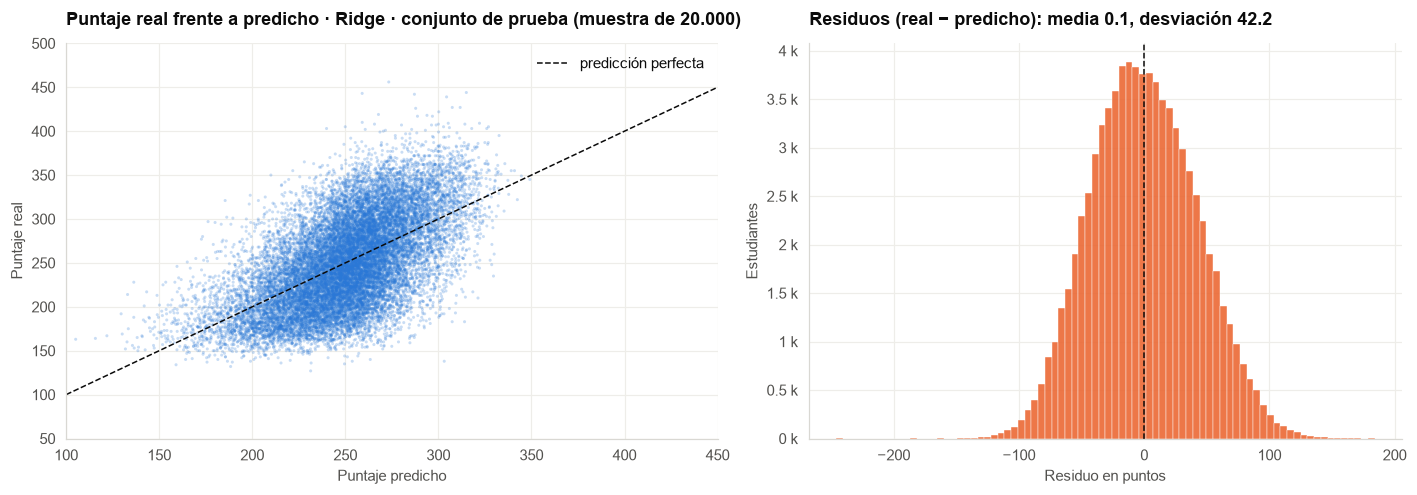

Sesgo del modelo por tramo de puntaje real:


tramo,"(0, 200]","(200, 250]","(250, 300]","(300, 350]","(350, 500]"
n,"15,524.00","26,372.00","23,352.00","12,332.00","2,338.00"
residuo medio,-44.00,-17.50,15.80,48.10,80.00
MAE,45.80,25.70,23.80,48.60,80.00


In [13]:
pred_test = ridge.predict(Xl_test)
resid = y_test - pred_test
muestra = np.random.default_rng(RANDOM_STATE).choice(len(y_test), 20_000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].scatter(pred_test[muestra], y_test.values[muestra], s=4, alpha=0.25, color=C_BASE, edgecolors="none")
lims = [100, 450]
axes[0].plot(lims, lims, color=TINTA, linewidth=1, linestyle="--", label="predicción perfecta")
axes[0].set_xlim(lims); axes[0].set_ylim(50, 500)
axes[0].set_title("Puntaje real frente a predicho · Ridge · conjunto de prueba (muestra de 20.000)")
axes[0].set_xlabel("Puntaje predicho"); axes[0].set_ylabel("Puntaje real"); axes[0].legend(frameon=False)

axes[1].hist(resid, bins=80, color=C_ACCENT, alpha=0.9, edgecolor="white", linewidth=0.3)
axes[1].axvline(0, color=TINTA, linewidth=1, linestyle="--")
axes[1].set_title(f"Residuos (real − predicho): media {resid.mean():.1f}, desviación {resid.std():.1f}")
axes[1].set_xlabel("Residuo en puntos"); axes[1].set_ylabel("Estudiantes")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1000:g} k"))
fig.tight_layout()
save_fig(fig, "baseline_diagnostics")
plt.show()

por_tramo = pd.DataFrame({"real": y_test, "pred": pred_test}).assign(
    tramo=lambda d: pd.cut(d["real"], [0, 200, 250, 300, 350, 500]))
sesgo = por_tramo.groupby("tramo", observed=True).apply(
    lambda g: pd.Series({"n": len(g), "residuo medio": (g["real"] - g["pred"]).mean(),
                         "MAE": (g["real"] - g["pred"]).abs().mean()})).round(1)
print("Sesgo del modelo por tramo de puntaje real:")
display(sesgo.T)

Los residuos están centrados (media 0,1) con desviación de 42,2 puntos y forma de campana, pero el panel izquierdo muestra el límite estructural del modelo lineal: la nube se aplana respecto de la diagonal. El modelo **predice casi todo entre 180 y 330 puntos**, comprime los extremos y por eso su sesgo depende del tramo:

| Tramo de puntaje real | Residuo medio | MAE |
|---|---|---|
| 0 a 200 | −44,0 | 45,8 |
| 200 a 250 | −17,5 | 25,7 |
| 250 a 300 | +15,8 | 23,8 |
| 300 a 350 | +48,1 | 48,6 |
| 350 a 500 | +80,0 | 80,0 |

A los estudiantes de puntaje bajo les asigna más de lo que obtienen y a los de puntaje alto, mucho menos: a quienes superan 350 puntos los subestima en 80 puntos en promedio. Es el patrón esperado cuando las variables explicativas capturan el contexto del estudiante pero no su desempeño individual, y es la señal de no linealidad e interacciones que los modelos de árboles de la fase 3 deben aprovechar.

### 8.3 Qué aprendió el modelo de referencia

Los coeficientes de Ridge sobre variables estandarizadas y *one-hot* se leen como puntos de diferencia respecto de la categoría de referencia, o por desviación estándar en las numéricas. Se grafican los 20 de mayor magnitud para confirmar que el modelo recoge las asociaciones de la fase 1 y para identificar cuáles de ellas se mantienen una vez se controlan todas las demás.

Figura guardada: assets\images\data\baseline_coefficients.png


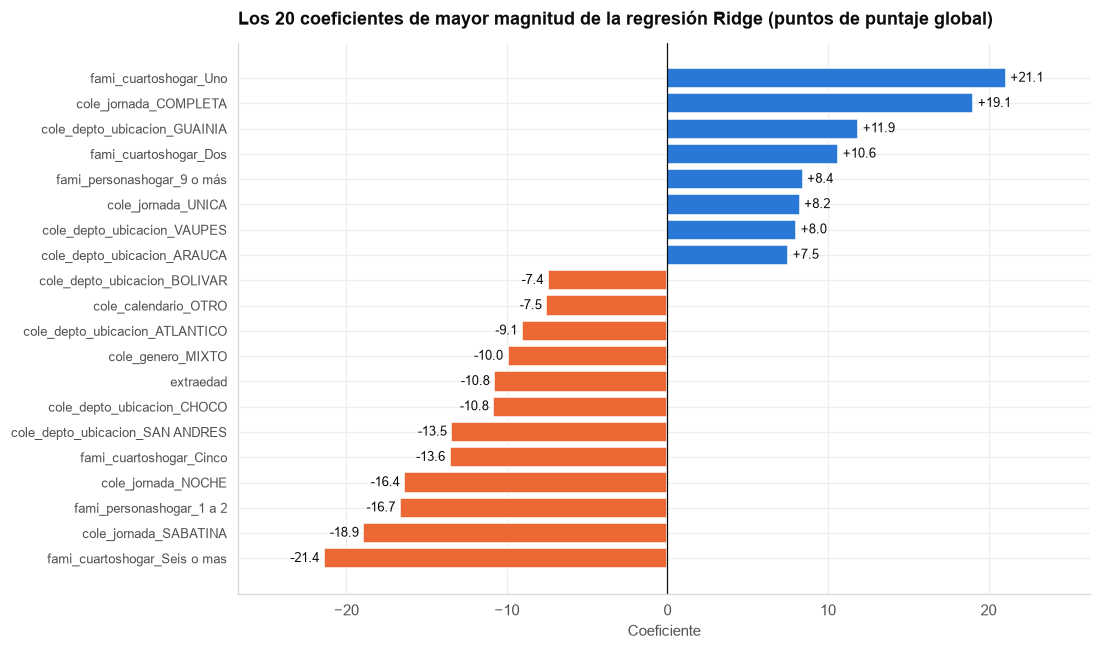

In [14]:
coefs = pd.Series(ridge.coef_, index=Xl_train.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index[:20]).sort_values()

fig, ax = plt.subplots(figsize=(10, 6.5))
bars = ax.barh(top.index, top.values, color=[C_BASE if v > 0 else C_ACCENT for v in top.values])
ax.bar_label(bars, labels=[f"{v:+.1f}" for v in top.values], padding=3, fontsize=8.5)
ax.axvline(0, color=TINTA, linewidth=0.8)
ax.set_title("Los 20 coeficientes de mayor magnitud de la regresión Ridge (puntos de puntaje global)")
ax.set_xlabel("Coeficiente"); ax.tick_params(axis="y", labelsize=8.5)
ax.set_xlim(top.min() * 1.25, top.max() * 1.25)
save_fig(fig, "baseline_coefficients")
plt.show()

Los coeficientes confirman las asociaciones de la fase 1 una vez se controlan todas las demás variables: la **jornada** sigue siendo la variable del colegio con mayor efecto propio (completa +19,1, única +8,2, nocturna −16,4, sabatina −18,9 respecto de la mañana), la **extraedad** resta 10,8 puntos y varios **departamentos** mantienen un efecto después de descontar el municipio (Chocó −10,8, San Andrés −13,5, Atlántico −9,1).

Dos lecturas requieren cuidado. Primero, los coeficientes de **cuartos** y **personas** del hogar (un cuarto +21,1, seis o más −21,4; nueve o más personas +8,4, una o dos −16,7) tienen signos que contradicen la intuición porque conviven con la variable derivada `personas_por_cuarto`: el modelo reparte el efecto del hacinamiento entre tres columnas colineales y los coeficientes individuales dejan de leerse por separado. Segundo, **Guainía, Vaupés y Arauca** aparecen con coeficientes positivos aunque son departamentos de bajo puntaje: el municipio codificado por objetivo ya absorbe su nivel, y el coeficiente del departamento solo corrige el remanente. Para interpretar la contribución de cada variable de forma robusta, la fase 3 usará importancia por permutación y valores SHAP en lugar de coeficientes.

## 9. Conclusiones de la fase 2

*   El conjunto de trabajo de la fase 2 queda en **532.792 estudiantes y 27 variables explicativas**, construido aplicando las doce decisiones del análisis exploratorio: sin duplicados, sin los puntajes por área, con los faltantes del cuestionario convertidos en información (categoría *No respondió* e indicador de cuestionario incompleto) y con cinco variables derivadas (edad, extraedad, personas por cuarto e indicadores de educación desconocida). Está guardado en `data/processed/`, junto con la partición y los preprocesadores, para que las fases siguientes trabajen sobre las mismas filas.

*   La partición **70/15/15 estratificada por deciles** deja 372.954, 79.919 y 79.919 estudiantes con distribuciones idénticas del puntaje (media 250,1, desviación 51,8 en las tres partes) y sin solapamiento, de modo que las métricas en prueba son una estimación limpia del desempeño.

*   El **modelo de referencia es una regresión Ridge con MAE de 34,15 puntos, RMSE de 42,17 y R² de 0,338 en prueba**, idénticos a los de entrenamiento y validación. Mejora en 8,8 puntos de MAE al modelo ingenuo y en casi diez puntos porcentuales de R² al ajuste exploratorio de la fase 1; la regularización resultó innecesaria con este volumen de datos (`alpha` = 0,01), pero se mantiene por la estabilidad de los coeficientes.

*   El diagnóstico muestra el límite del modelo lineal: **comprime los extremos**, sobreestima a los estudiantes de menos de 200 puntos en 44 puntos y subestima a los de más de 350 en 80. Ese sesgo por tramo, junto con los coeficientes inestables de las variables colineales, es la evidencia concreta de que la fase 3 necesita modelos capaces de capturar no linealidades e interacciones, y de que la interpretación debe hacerse con importancia por permutación y SHAP, no con coeficientes.

*   Para la fase 3 queda fijado el protocolo: mismos datos y partición, dos representaciones ya ajustadas (`prep_lineal` y `prep_arboles` en `models/`), Ridge como referencia a superar, y la meta de reducir el MAE por debajo de 34 puntos y elevar el R² por encima de 0,34 con boosting por histogramas y bosques aleatorios.